In [1]:
import os
import sys
import math

import joblib
import glob
import pandas as pd
import numpy as np
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

sys.path.insert(0, '../../..') # Load Parent directory to import utils
from utils.constants import Configs

RESULTS_DIR = Configs._wrist_only_loso_results_cache_dir

In [2]:
def load_all_fold_results(results_dir):
    rows = []

    for file in glob.glob(os.path.join(results_dir, "*.pkl")):
        obj = joblib.load(file)

        if isinstance(obj, dict) and "Fold_History" in obj:
            df = pd.DataFrame(obj["Fold_History"])

            # Recover metadata from the filename:
            # wrist_only_loso_results_{model}_{representation}_{movement}.pkl
            stem = Path(file).stem.replace("wrist_only_loso_results_", "")
            model, representation, phase = stem.rsplit("_", 2)

            df["Model"] = model
            df["Representation"] = representation
            df["Phase"] = phase
            rows.append(df)

        elif isinstance(obj, pd.DataFrame):
            rows.append(obj)

        else:
            raise TypeError(f"{file} contains {type(obj).__name__}, not a supported result format")

    return pd.concat(rows, ignore_index=True)

In [3]:
# Load the data and verify the first few rows
consolidated_data = load_all_fold_results(RESULTS_DIR)
print(f"Successfully loaded {len(consolidated_data)} fold records.")

consolidated_data.head()

Successfully loaded 418 fold records.


,subject_out,params,metrics,dtw_radius,dropped_features,Model,Representation,Phase
0,1,{'z_threshold': 2.0},"{'AUPRC': nan, 'AUROC': nan, 'TP': 0, 'FP': 0,...",0.1,None,ZScore,ShapeBased,Move
1,2,{'z_threshold': 2.0},"{'AUPRC': nan, 'AUROC': nan, 'TP': 1, 'FP': 0,...",0.1,None,ZScore,ShapeBased,Move
2,3,{'z_threshold': 2.0},"{'AUPRC': nan, 'AUROC': nan, 'TP': 0, 'FP': 0,...",0.1,None,ZScore,ShapeBased,Move
3,4,{'z_threshold': 2.0},"{'AUPRC': nan, 'AUROC': nan, 'TP': 1, 'FP': 0,...",0.1,None,ZScore,ShapeBased,Move
4,5,{'z_threshold': 2.5},"{'AUPRC': nan, 'AUROC': nan, 'TP': 0, 'FP': 0,...",0.1,None,ZScore,ShapeBased,Move


In [4]:
def plot_subject_variance(phases, target_rep, metric_col='F2', metric_label='F2-Score'):
    width = 10
    height = width * (len(phases) / 5)  # Adjust height based on the number of phases
    fig, axes = plt.subplots(1, len(phases), figsize=(width, height), dpi=300)

    metric_col = metric_col.upper()  # Ensure metric column is uppercase for consistency

    # MCC já está na escala [-1, 1] / percentagem própria -- não faz sentido multiplicar
    # por 100 nem fixar o eixo Y em [-5, 105] como fazemos para métricas 0-1 (F1/F2/Precision/Recall).
    is_bounded_0_1 = metric_col not in ('MCC',)
    scale_factor = 100 if is_bounded_0_1 else 1
 
    for i, target_phase in enumerate(phases):
        filtered_df = consolidated_data[
                (consolidated_data['Phase'] == target_phase) &
                (consolidated_data['Representation'] == target_rep)
            ].copy()

        # Validate that the 'metrics' column contains dictionaries
        if not filtered_df['metrics'].map(lambda value: isinstance(value, dict)).all():
            raise TypeError("Expected each 'metrics' value to be a dictionary.")
        filtered_df['metric_scaled'] = filtered_df['metrics'].map(
            lambda metrics: metrics.get(metric_col, np.nan)
        ) * scale_factor
 
        if filtered_df['metric_scaled'].notna().sum() == 0:
            # Fase sem nenhum positivo conhecido (ex.: Place) -- nada a plotar
            axes[i].text(0.5, 0.5, f"No annotated positives\n({metric_label} not computable)",
                         ha='center', va='center', fontsize=10, color='gray',
                         transform=axes[i].transAxes)
            axes[i].set_title(f'Phase: {target_phase}', fontsize=12, fontweight='bold')
            axes[i].set_xticks([])
            axes[i].set_yticks([])
            continue
 
        sns.boxplot(data=filtered_df, x='Model', y='metric_scaled', color="#E0E0E0", showfliers=False, ax=axes[i])
        sns.stripplot(data=filtered_df, x='Model', y='metric_scaled', color="#D62728", alpha=0.6, jitter=True, size=5, ax=axes[i])
 
        axes[i].set_title(f'Phase: {target_phase}', fontsize=12, fontweight='bold')
        axes[i].set_ylabel(f'{metric_label}-Score (%)' if is_bounded_0_1 else metric_label, fontsize=11) if i == 0 else axes[i].set_ylabel('')
        axes[i].set_xlabel('', fontsize=11)
        axes[i].tick_params(axis='x', rotation=45, labelsize=10)
 
        if is_bounded_0_1:
            axes[i].set_ylim(-5, 105)
        else:
            axes[i].set_ylim(-1.05, 1.05)  # MCC: intervalo [-1, 1]
 
    fig.suptitle(f'Subject-Level Variance ({target_rep}) — Movement-Level {metric_label}')
    fig.tight_layout()
    plt.show()
 
phases = ['Pick', 'Move']

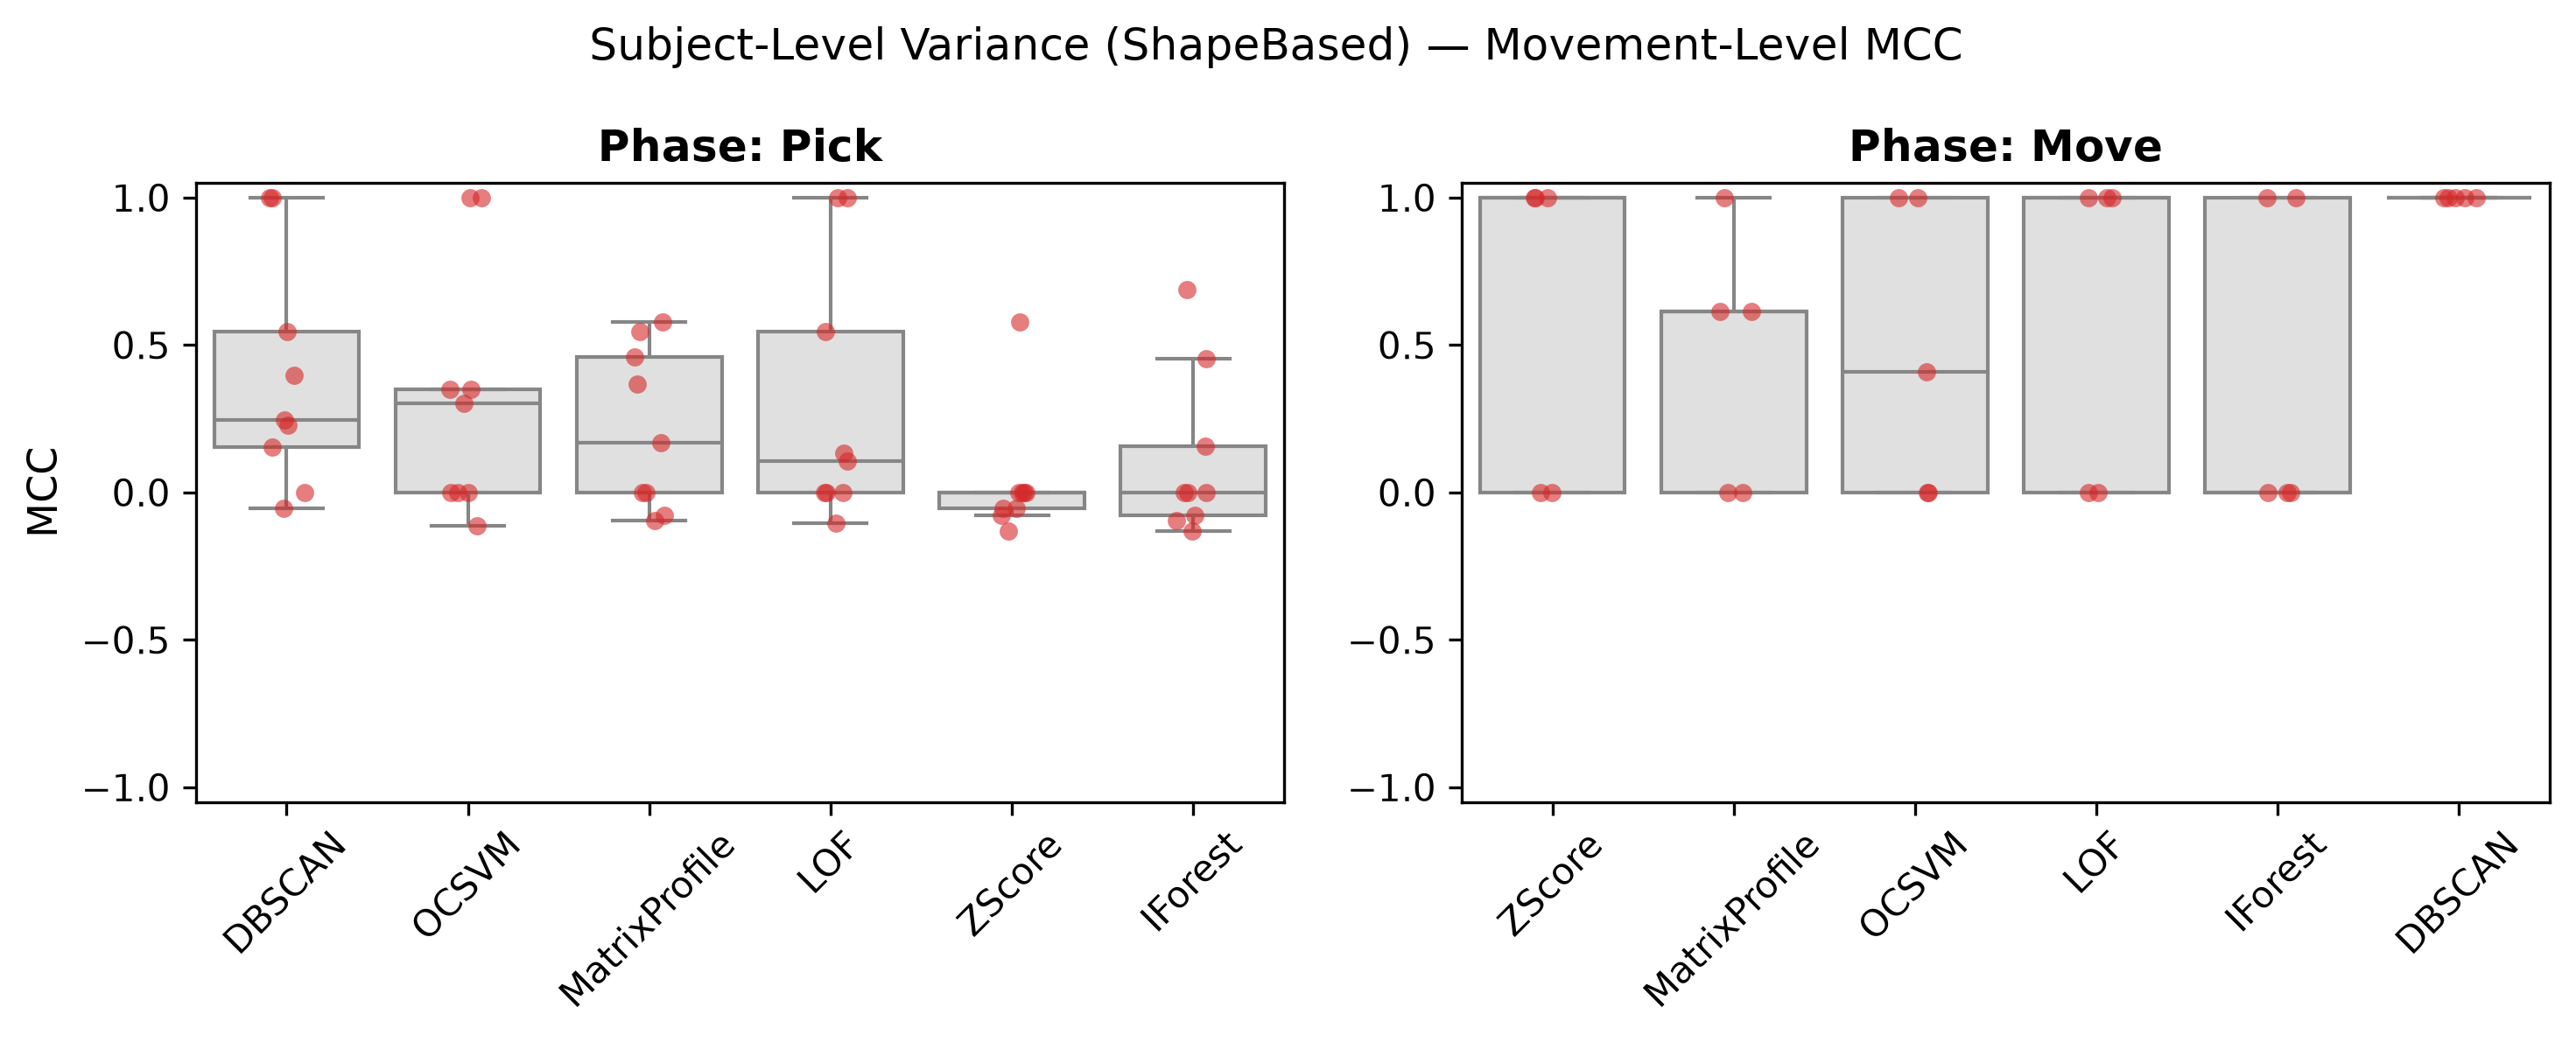

In [5]:
target_rep = 'ShapeBased'
plot_subject_variance(phases, target_rep, metric_col='MCC', metric_label='MCC')

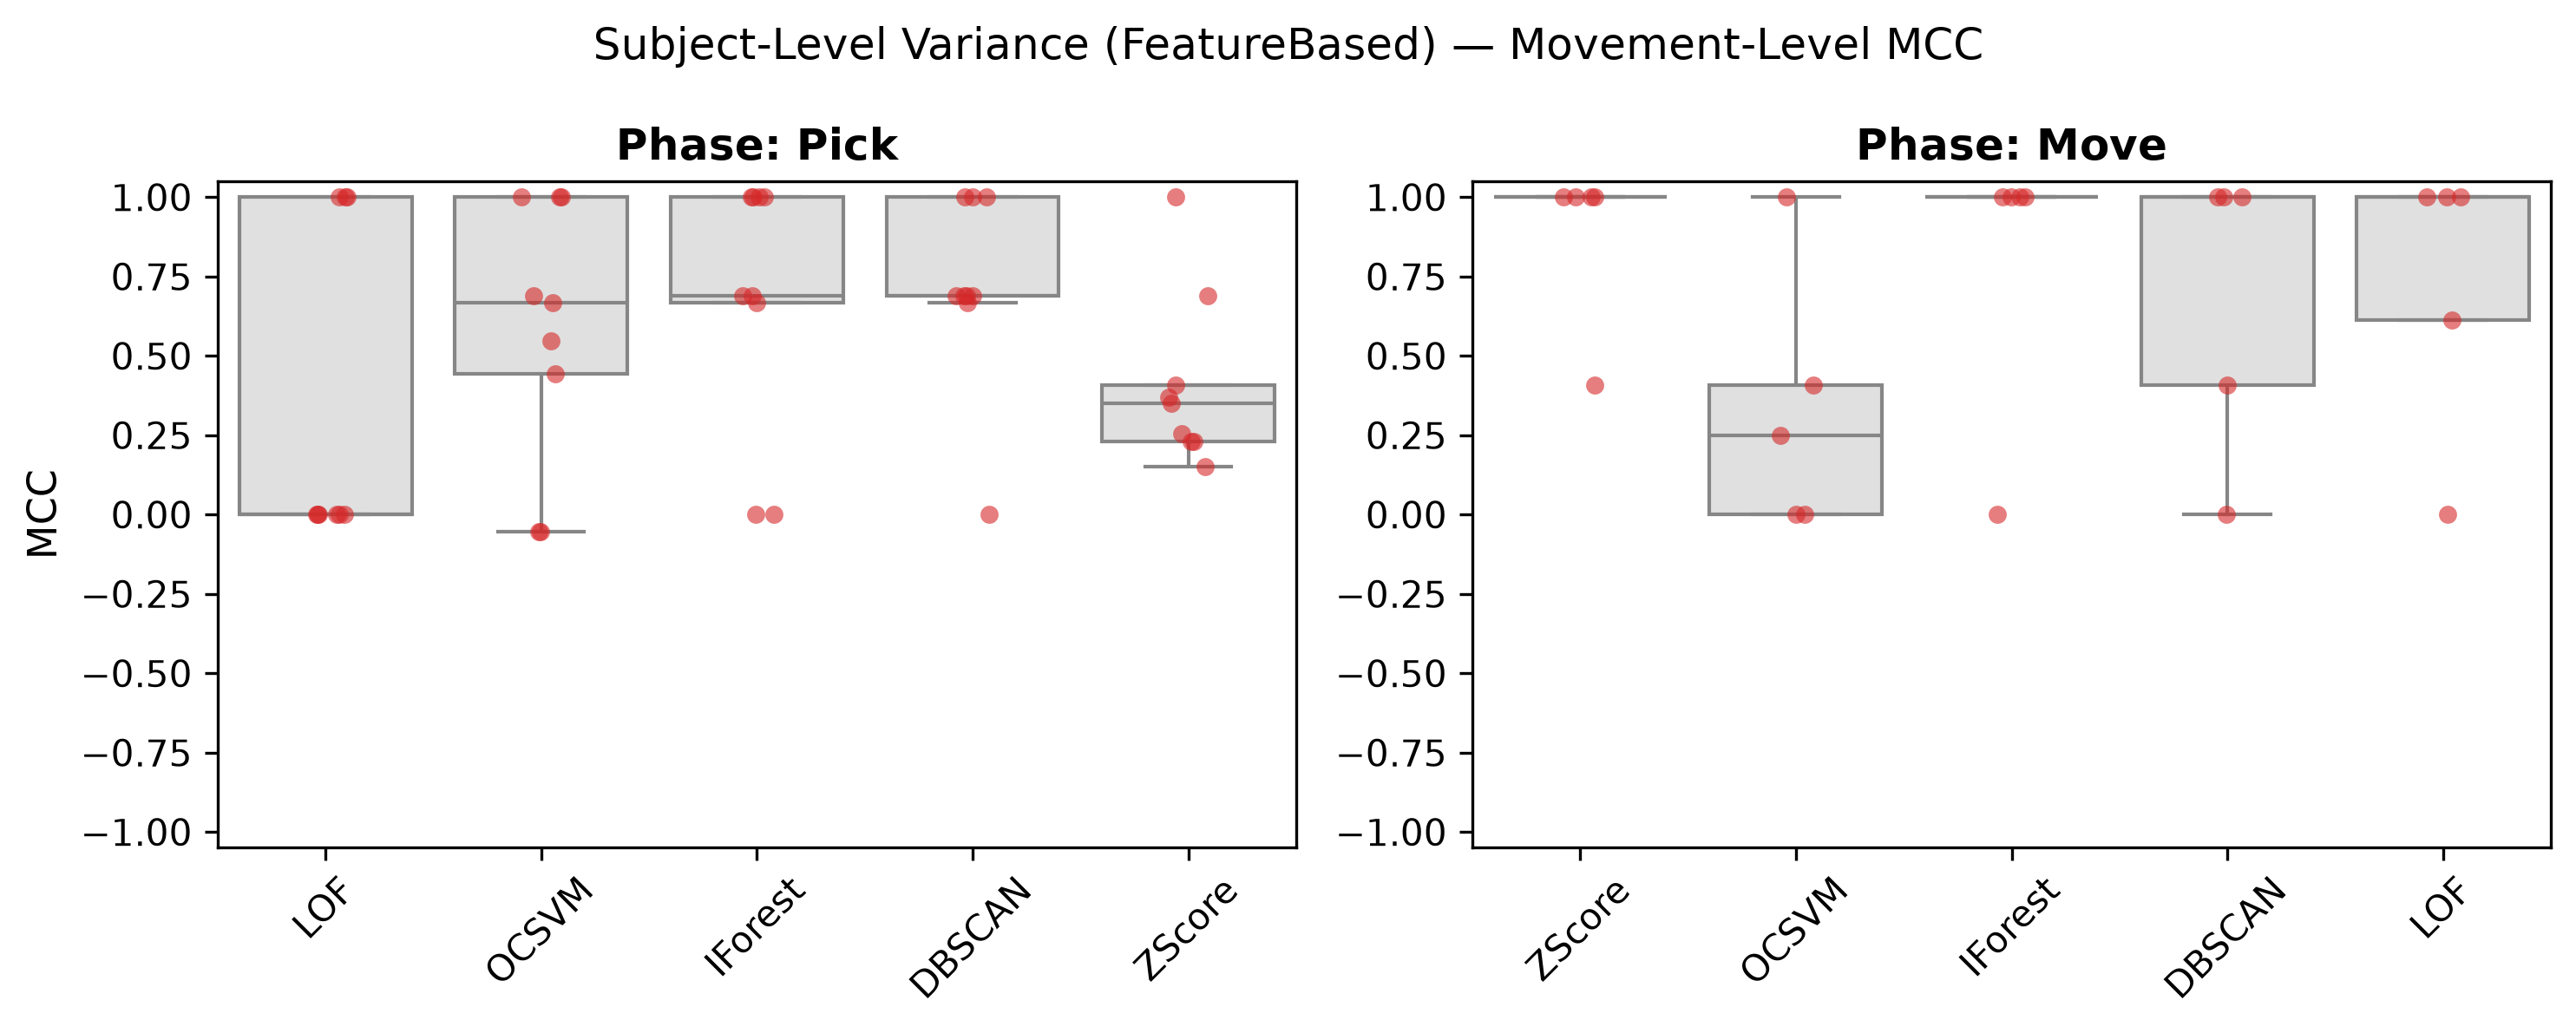

In [6]:
target_rep = 'FeatureBased'
plot_subject_variance(phases, target_rep, metric_col='MCC', metric_label='MCC')